# pixel2dag · Notebook 02 — Una imagen es una matriz de números

**Objetivo:** dar una **imagen de fondo de ojo** a cada paciente del notebook 01. Al terminar, `renderizar(simular_paciente(17))` te devolverá su retinografía, con sus lesiones y el efecto del escáner de su hospital.

**Aprenderás `numpy`** desde cero, solo lo necesario: crear matrices, indexar, hacer operaciones con toda la matriz a la vez, máscaras y *broadcasting*.

**Duración:** unos 60–75 minutos.

Las celdas son del mismo tipo que en el notebook 01: 🔍 **Ejemplo**, 🤔 **Predice**, ✏️ **Ejercicio** (sustituye `...`) y ✅ **Comprobación**.

### Código del notebook 01

Esta es la versión resuelta de lo que hiciste en el 01, para que este notebook funcione por sí solo. Si prefieres, sustitúyela por tu propio código. Solo ejecútala.

In [1]:
import random, math
import numpy as np
import matplotlib.pyplot as plt

def dado(semilla, variable):
    return random.Random(f"{semilla}-{variable}")

def lanzar_monedas(rng, n, p):
    return sum(rng.random() < p for _ in range(n))

def sigmoide(x):
    return 1 / (1 + math.exp(-x))

def prob_gravedad(edad, hospital):
    return sigmoide(-1 + 0.05 * (edad - 60) + 1.5 * (hospital == "A"))

PROB_MA = [0.0, 0.075, 0.2, 0.375, 0.625]
PROB_EX = [0.0, 0.0, 0.1, 0.25, 0.5]

def simular_paciente(semilla, do=None):
    do = do or {}
    hospital = do["hospital"] if "hospital" in do else ("A" if dado(semilla, "hospital").random() < 0.5 else "B")
    edad = do["edad"] if "edad" in do else dado(semilla, "edad").gauss(60, 10)
    gravedad = do["gravedad"] if "gravedad" in do else lanzar_monedas(dado(semilla, "gravedad"), 4, prob_gravedad(edad, hospital))
    n_ma = lanzar_monedas(dado(semilla, "ma"), 40, PROB_MA[gravedad])
    n_ex = lanzar_monedas(dado(semilla, "ex"), 20, PROB_EX[gravedad])
    return {"semilla": semilla, "hospital": hospital, "edad": edad, "gravedad": gravedad,
            "n_ma": n_ma, "n_ex": n_ex, "referable": int(gravedad >= 2)}

print(simular_paciente(17))

{'semilla': 17, 'hospital': 'A', 'edad': 64.78688512674223, 'gravedad': 3, 'n_ma': 18, 'n_ex': 4, 'referable': 1}


---
## Parte 1 · Una imagen es una matriz

### 🔍 Ejemplo: una imagen en blanco y negro

Para el ordenador, una imagen en escala de grises es una **tabla de números**: 0 es negro, 1 es blanco, y los valores intermedios son grises.

- `np.zeros((filas, columnas))` crea una matriz llena de ceros, es decir, una imagen negra.
- `img[fila, columna] = valor` cambia un píxel. **La fila va primero.** Las filas cuentan desde arriba y las columnas desde la izquierda, empezando en 0.
- `plt.imshow(img)` dibuja la matriz.

[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
forma: (5, 5)


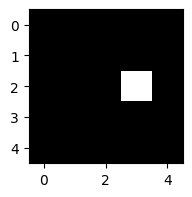

In [2]:
img = np.zeros((5, 5))
img[2, 3] = 1.0          # fila 2, columna 3
print(img)
print("forma:", img.shape)

plt.figure(figsize=(2, 2))
plt.imshow(img, cmap="gray", vmin=0, vmax=1)
plt.show()

### 🤔 Predice

En una imagen negra de 5×5, si hacemos `img[0, 4] = 1.0`, ¿en qué **esquina** aparecerá el píxel blanco?

Tu predicción: ...


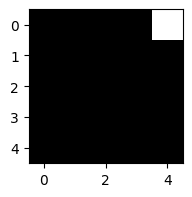

In [3]:
mi_prediccion = "..."
img = np.zeros((5, 5))
img[0, 4] = 1.0
print("Tu predicción:", mi_prediccion)
plt.figure(figsize=(2, 2)); plt.imshow(img, cmap="gray", vmin=0, vmax=1); plt.show()

### 🔍 Ejemplo: pintar zonas enteras con *slicing*

Igual que con las listas de Python, `a:b` significa "desde `a` hasta `b`, **sin incluir** `b`". En una matriz se puede hacer en las dos dimensiones a la vez:

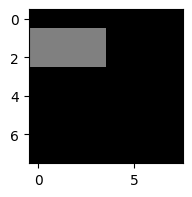

In [4]:
img = np.zeros((8, 8))
img[1:3, 0:4] = 0.5      # filas 1 y 2, columnas 0 a 3 → un rectángulo gris
plt.figure(figsize=(2, 2)); plt.imshow(img, cmap="gray", vmin=0, vmax=1); plt.show()

### ✏️ Ejercicio 1.1

En una imagen negra de 8×8, pinta de **blanco un cuadrado de 3×3 en la esquina inferior derecha**: las tres últimas filas y las tres últimas columnas.

<details><summary>▶ Pista</summary>

Las tres últimas filas de una imagen de 8 son la 5, la 6 y la 7, así que `5:8`.
</details>

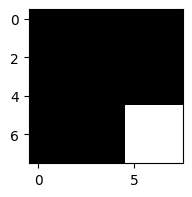

In [5]:
cuadrado = np.zeros((8, 8))
cuadrado[5:8,5:8] = 1
plt.figure(figsize=(2, 2)); plt.imshow(cuadrado, cmap="gray", vmin=0, vmax=1); plt.show()

In [6]:
# ✅ Comprobación
assert cuadrado.sum() == 9, f"Deberían ser 9 píxeles blancos; tienes {cuadrado.sum():.0f}"
assert cuadrado[7, 7] == 1 and cuadrado[5, 5] == 1 and cuadrado[4, 4] == 0, "El cuadrado no está en la esquina correcta"
print("✅ Correcto")

✅ Correcto


### 🔍 Ejemplo: imágenes en color

Una imagen en color tiene **tres capas**: rojo, verde y azul (RGB). Su forma es `(filas, columnas, 3)`, y cada píxel es una lista de tres valores entre 0 y 1.

forma: (4, 4, 3)


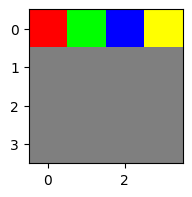

In [7]:
img = np.zeros((4, 4, 3))
img[0, 0] = [1, 0, 0]        # rojo
img[0, 1] = [0, 1, 0]        # verde
img[0, 2] = [0, 0, 1]        # azul
img[0, 3] = [1, 1, 0]        # rojo + verde = amarillo
img[1:4, :] = [0.5, 0.5, 0.5]  # ":" significa "todas" → filas 1 a 3, todas las columnas, en gris
print("forma:", img.shape)
plt.figure(figsize=(2, 2)); plt.imshow(img); plt.show()

### ✏️ Ejercicio 1.2

Crea una imagen de 64×64 en color y píntala **entera** de naranja rojizo `[0.8, 0.35, 0.15]`, el color típico de una retina. Es una línea para crearla y otra para pintarla.

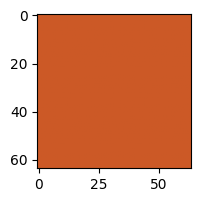

In [8]:
naranja = np.zeros((64, 64, 3))
naranja[:] = [0.8, 0.35, 0.15]
...
plt.figure(figsize=(2, 2)); plt.imshow(naranja); plt.show()

In [9]:
# ✅ Comprobación
assert naranja.shape == (64, 64, 3), f"La forma debería ser (64, 64, 3); es {naranja.shape}"
assert np.allclose(naranja[10, 20], [0.8, 0.35, 0.15]) and np.allclose(naranja[63, 63], [0.8, 0.35, 0.15])
print("✅ Correcto")

✅ Correcto


---
## Parte 2 · Operar con toda la imagen a la vez

### 🔍 Ejemplo: operaciones elemento a elemento

La gran ventaja de `numpy` es que las operaciones se aplican a **todos los elementos a la vez**, sin bucles.

In [10]:
a = np.array([1.0, 2.0, 3.0])
b = np.array([10.0, 20.0, 30.0])
print("a + b    =", a + b)
print("a * 2    =", a * 2)
print("a ** 2   =", a ** 2)
print("np.sqrt(b) =", np.sqrt(b))
print("a > 1.5  =", a > 1.5)      # ¡una comparación da un array de True/False!

a + b    = [11. 22. 33.]
a * 2    = [2. 4. 6.]
a ** 2   = [1. 4. 9.]
np.sqrt(b) = [3.16227766 4.47213595 5.47722558]
a > 1.5  = [False  True  True]


### 🔍 Ejemplo: la distancia de cada píxel al centro

Para dibujar un círculo necesitamos saber **a qué distancia del centro está cada píxel**. `np.mgrid` crea dos matrices: una con el número de fila de cada píxel y otra con el número de columna.

In [11]:
filas, cols = np.mgrid[0:5, 0:5]
print("filas:\n", filas)
print("cols:\n", cols)

filas:
 [[0 0 0 0 0]
 [1 1 1 1 1]
 [2 2 2 2 2]
 [3 3 3 3 3]
 [4 4 4 4 4]]
cols:
 [[0 1 2 3 4]
 [0 1 2 3 4]
 [0 1 2 3 4]
 [0 1 2 3 4]
 [0 1 2 3 4]]


Con eso, la distancia de cada píxel al centro sale con Pitágoras, **para toda la imagen de una vez**:

$$d = \sqrt{(\text{fila} - c)^2 + (\text{columna} - c)^2}$$

Definimos las constantes que usaremos durante todo el notebook:

forma de D: (64, 64)
distancia en la esquina: 44.5 | junto al centro (32, 32): 0.7


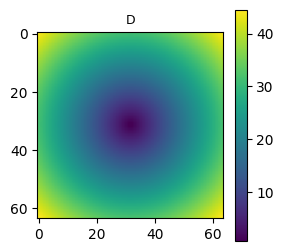

In [12]:
IMG = 64                       # tamaño de la imagen
C = (IMG - 1) / 2              # centro (31.5)
R = IMG * 0.46                 # radio del disco de la retina
YY, XX = np.mgrid[0:IMG, 0:IMG]

D = np.sqrt((YY - C) ** 2 + (XX - C) ** 2)   # distancia al centro, para cada píxel
print("forma de D:", D.shape)
print("distancia en la esquina:", round(D[0, 0], 1), "| junto al centro (32, 32):", round(D[32, 32], 1))
plt.figure(figsize=(3, 3)); plt.imshow(D); plt.colorbar(); plt.title("D", fontsize=9); plt.show()

### 🔍 Ejemplo: máscaras

Una comparación como `D <= R` da una matriz de `True`/`False`, que llamamos **máscara**. Si la usas como índice, `img[mascara] = color`, solo se pintan los píxeles donde vale `True`.

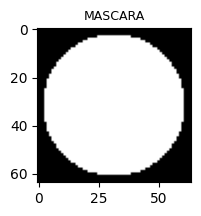

In [13]:
MASCARA = D <= R
plt.figure(figsize=(2, 2)); plt.imshow(MASCARA, cmap="gray"); plt.title("MASCARA", fontsize=9); plt.show()

### ✏️ Ejercicio 2.1 · El disco de la retina

Crea `disco`: una imagen **negra** de 64×64 en color con el disco pintado de `[0.8, 0.35, 0.15]` **solo dentro de la máscara**.

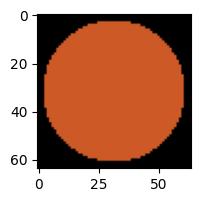

In [14]:
disco = np.zeros((64, 64, 3))
disco[MASCARA] = [0.8, 0.35, 0.15]
...
plt.figure(figsize=(2, 2)); plt.imshow(disco); plt.show()

In [15]:
# ✅ Comprobación
assert disco.shape == (64, 64, 3)
assert np.allclose(disco[0, 0], 0), "Las esquinas (fuera del disco) deben ser negras"
assert np.allclose(disco[32, 32], [0.8, 0.35, 0.15]), "El centro debe ser naranja"
print("✅ Correcto")

✅ Correcto


### 🔍 Ejemplo: *broadcasting*

Queremos oscurecer los bordes del disco, como en una retinografía real. Para eso multiplicamos cada píxel por un factor que depende de su distancia: `1 - 0.35 * (D/R)**2`, que vale 1 en el centro y 0.65 en el borde.

Pero hay un problema de formas: el factor es `(64, 64)` y la imagen es `(64, 64, 3)`. Si añadimos una dimensión con `[..., None]`, el factor pasa a ser `(64, 64, 1)`, y `numpy` lo **repite automáticamente** en las 3 capas de color. Eso se llama *broadcasting*.

In [17]:
factor = 1 - 0.35 * (D / R) ** 2
print("factor:", factor.shape, "→ con [..., None]:", factor[..., None].shape, "| imagen:", disco.shape)

# Mini ejemplo: una "imagen" de 1x2 píxeles RGB por un factor de 1x2
mini = np.array([[[1.0, 1.0, 1.0], [1.0, 1.0, 1.0]]])   # forma (1, 2, 3)
f = np.array([[1.0, 0.5]])                              # forma (1, 2)
print(mini * f[..., None])                              # el 2.º píxel queda a la mitad en las 3 capas

factor: (64, 64) → con [..., None]: (64, 64, 1) | imagen: (64, 64, 3)
[[[1.  1.  1. ]
  [0.5 0.5 0.5]]]


### ✏️ Ejercicio 2.2

Crea `disco_sombra`: el `disco` multiplicado por el `factor` (con `[..., None]`). Es una línea.

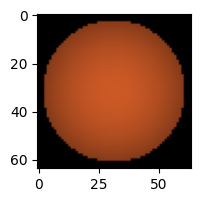

In [18]:
disco_sombra = disco * factor[..., None]
plt.figure(figsize=(2, 2)); plt.imshow(disco_sombra); plt.show()

In [19]:
# ✅ Comprobación
assert disco_sombra.shape == (64, 64, 3), "¿Has usado factor[..., None]?"
assert disco_sombra[32, 32, 0] > disco_sombra[32, 60, 0], "El borde debería ser más oscuro que el centro"
print("✅ Correcto")

✅ Correcto


---
## Parte 3 · Manchas: la pieza con la que dibujamos todo

Todo lo demás (nervio óptico, vasos, microaneurismas, exudados) serán **manchas redondas difuminadas** de distintos tamaños y colores.

### 🔍 Ejemplo: el "peso" de una mancha

Para una mancha centrada en `(cy, cx)` con radio `r`, cada píxel recibe un peso `w` entre 0 y 1. Vale 1 en el centro y baja suavemente al alejarse. Es una campana de Gauss, como la normal que viste en probabilidad:

$$w = \alpha \cdot \exp\left(-\frac{(\text{fila} - c_y)^2 + (\text{columna} - c_x)^2}{2r^2}\right)$$

`alpha` controla la opacidad: con 1 la mancha es opaca y con 0.5 es medio transparente.

w en el centro: 1.0 | a 4 px: 0.61 | lejos: 0.0


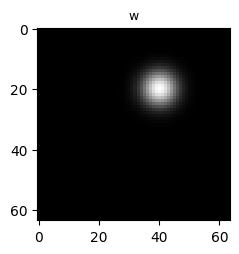

In [20]:
cy, cx, r, alpha = 20, 40, 4, 1.0
w = alpha * np.exp(-((YY - cy) ** 2 + (XX - cx) ** 2) / (2 * r ** 2))
print("w en el centro:", round(w[20, 40], 2), "| a 4 px:", round(w[20, 44], 2), "| lejos:", round(w[0, 0], 4))
plt.figure(figsize=(2.5, 2.5)); plt.imshow(w, cmap="gray"); plt.title("w", fontsize=9); plt.show()

### 🔍 Ejemplo: mezclar colores

Para pintar la mancha, cada píxel se convierte en una **media ponderada** entre su color actual y el color de la mancha:

$$\text{nuevo} = (1 - w)\cdot\text{actual} + w\cdot\text{color}$$

Con `w = 1` el píxel queda del color de la mancha; con `w = 0`, no cambia; con `w = 0.5`, queda a medio camino. Míralo con un solo píxel:

In [21]:
actual = np.array([0.8, 0.35, 0.15])   # naranja
color  = np.array([1.0, 0.92, 0.35])   # amarillo
for w_ in [0.0, 0.5, 1.0]:
    print(f"w={w_}: {(1 - w_) * actual + w_ * color}")

w=0.0: [0.8  0.35 0.15]
w=0.5: [0.9   0.635 0.25 ]
w=1.0: [1.   0.92 0.35]


### ✏️ Ejercicio 3.1 · `pintar_mancha(img, cy, cx, radio, color, alpha)`

Junta los dos ejemplos anteriores:
1. Calcula `w` como en el primero, usando `cy`, `cx`, `radio` y `alpha`.
2. Devuelve la mezcla del segundo. Ojo: `w` es `(64, 64)` y la imagen `(64, 64, 3)`, así que usa `w[..., None]`. El `color` conviértelo con `np.array(color)`.

La función **devuelve una imagen nueva**, sin modificar la original.

In [22]:
def pintar_mancha(img, cy, cx, radio, color, alpha=1.0):
    # 1. Calculamos w
    w = alpha * np.exp(-((YY - cy) ** 2 + (XX - cx) ** 2) / (2 * radio ** 2))

    # 2. Convertimos w a (64, 64, 1) añadiendo una dimensión extra
    w_ = w[..., None]

    # 3. Convertimos la lista de color a un array de NumPy para poder multiplicarlo
    color_arr = np.array(color)

    # 4. Asignamos la mezcla a una nueva variable (no sobreescribimos img)
    resultado = (1 - w_) * img + w_ * color_arr

    # 5. Devolvemos la imagen nueva (en tu código estabas devolviendo la original)
    return resultado

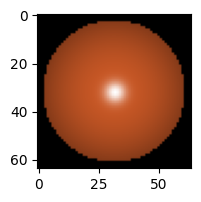

✅ ¡Ya puedes dibujar cualquier cosa con manchas!


In [23]:
# ✅ Comprobación
prueba = pintar_mancha(disco_sombra, 32, 32, 3, [1, 1, 1], 1.0)
assert prueba is not None and prueba.shape == (64, 64, 3), "Devuelve una imagen de forma (64, 64, 3) (¿has puesto w[..., None]?)"
assert np.allclose(prueba[32, 32], [1, 1, 1]), "En el centro de una mancha opaca el color debe ser exactamente el de la mancha"
assert np.allclose(prueba[0, 0], disco_sombra[0, 0], atol=1e-6), "Lejos de la mancha la imagen no debe cambiar"
media = pintar_mancha(disco_sombra, 32, 32, 3, [1, 1, 1], 0.5)
assert np.allclose(media[32, 32], 0.5 * disco_sombra[32, 32] + 0.5), "Revisa cómo usas alpha"
plt.figure(figsize=(2, 2)); plt.imshow(prueba); plt.show()
print("✅ ¡Ya puedes dibujar cualquier cosa con manchas!")

### ✏️ Ejercicio 3.2 · El nervio óptico

En una retinografía se ve como un **disco amarillo claro** a un lado. Píntalo sobre `disco_sombra` en la posición `(32, 48)`, con radio 4, color `[0.98, 0.85, 0.55]` y alpha 0.95. Guárdalo en `con_nervio`.

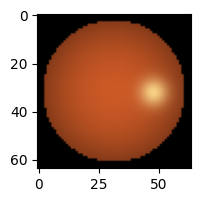

In [24]:
con_nervio = pintar_mancha(disco_sombra, 32,48,4,[0.98, 0.85, 0.55],0.95)
plt.figure(figsize=(2, 2)); plt.imshow(con_nervio); plt.show()

In [25]:
# ✅ Comprobación
assert np.allclose(con_nervio, pintar_mancha(disco_sombra, 32, 48, 4, [0.98, 0.85, 0.55], 0.95))
print("✅ Correcto")

✅ Correcto


### 🔍 Ejemplo: los vasos sanguíneos

Un vaso es una **cadena de manchas pequeñas** que avanza a pasos desde el nervio óptico, girando un poco al azar en cada paso, hasta salir del disco. No tienes que escribirlo, pero léelo: solo usa cosas que ya conoces.

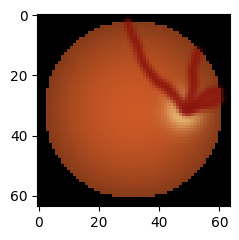

In [26]:
def dibujar_vasos(img, semilla, ny, nx):
    rng = dado(semilla, "vasos")
    for _ in range(4):                                   # 4 vasos
        y, x = ny, nx                                    # salen del nervio óptico
        angulo = rng.uniform(0, 2 * math.pi)
        grosor = 1.2
        for paso in range(60):
            angulo += rng.gauss(0, 0.18)                 # gira un poco al azar
            y += math.sin(angulo)
            x += math.cos(angulo)
            if math.hypot(y - C, x - C) > R:             # si sale del disco, se acaba
                break
            img = pintar_mancha(img, y, x, grosor, [0.55, 0.08, 0.05], 0.6)
            grosor = max(0.5, grosor * 0.99)             # se va estrechando
    return img

plt.figure(figsize=(2.5, 2.5)); plt.imshow(dibujar_vasos(con_nervio, 17, 32, 48)); plt.show()

### ✏️ Ejercicio 3.3 · `fondo_de_ojo(semilla)`

Junta en una función todo lo de las partes 2 y 3: disco → sombra → nervio óptico → vasos. Cada paso es una línea que ya has escrito.

Lo único nuevo: el nervio óptico estará a la **izquierda o a la derecha** según el paciente. Esa línea ya te la damos.

In [41]:
def fondo_de_ojo(semilla):
    lado = dado(semilla, "lado").choice([-1, 1])     # -1 = izquierda, 1 = derecha
    ny, nx = 32, C + lado * 16                        # posición del nervio óptico

    img = np.zeros((64,64,3))                        # 1. imagen negra 64x64x3
    img[MASCARA] = [0.8, 0.35, 0.15]               # 2. pinta el disco naranja con la MASCARA
    img = img * factor[..., None]           # 3. multiplica por el factor de sombra
    img = pintar_mancha(img,ny,nx,4, [0.98, 0.85, 0.55], 0.95)          # 4. nervio óptico en (ny, nx), radio 4, [0.98, 0.85, 0.55], alpha 0.95
    img = dibujar_vasos(img,semilla,ny,nx)         # 5. vasos
    return img

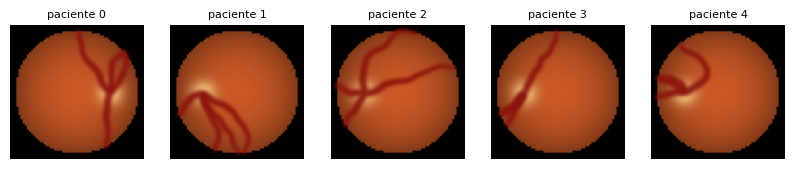

✅ Cada paciente tiene su propio fondo de ojo


In [42]:
# ✅ Comprobación
f17 = fondo_de_ojo(17)
assert f17.shape == (64, 64, 3)
assert np.allclose(f17, fondo_de_ojo(17)), "La misma semilla debe dar la misma imagen"
assert not np.allclose(f17, fondo_de_ojo(18)), "Pacientes distintos deberían tener fondos distintos"
assert np.allclose(f17[0, 0], 0) and f17[MASCARA].mean() > 0.2
fig, axs = plt.subplots(1, 5, figsize=(10, 2))
for s, ax in enumerate(axs):
    ax.imshow(fondo_de_ojo(s)); ax.set_title(f"paciente {s}", fontsize=8); ax.axis("off")
plt.show()
print("✅ Cada paciente tiene su propio fondo de ojo")

---
## Parte 4 · Las lesiones del paciente

### 🔍 Ejemplo: un punto al azar dentro del disco

Para colocar una lesión necesitamos un punto aleatorio **dentro del círculo**. Sorteamos un ángulo y una distancia al centro.

Un detalle de probabilidad: si la distancia fuera uniforme, los puntos se amontonarían en el centro, porque los anillos exteriores tienen más área. Tomar la **raíz cuadrada** de un uniforme lo compensa y reparte los puntos de forma uniforme por el área.

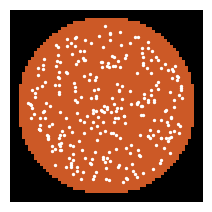

In [29]:
def posicion_en_disco(rng):
    distancia = R * 0.9 * math.sqrt(rng.random())
    angulo = rng.uniform(0, 2 * math.pi)
    return C + distancia * math.sin(angulo), C + distancia * math.cos(angulo)

rng = random.Random(0)
puntos = [posicion_en_disco(rng) for _ in range(300)]
plt.figure(figsize=(2.5, 2.5)); plt.imshow(disco)
plt.scatter([x for y, x in puntos], [y for y, x in puntos], s=2, c="white"); plt.axis("off"); plt.show()

### ✏️ Ejercicio 4.1 · `dibujar_microaneurismas(img, semilla, n_ma)`

Para cada uno de los `n_ma` microaneurismas: sortea una posición con `posicion_en_disco` y pinta una mancha de radio 0.8, color rojo oscuro `[0.35, 0, 0]` y alpha 0.95.

Usa **un solo** `rng = dado(semilla, "pos_ma")`, creado antes del bucle.

In [30]:
def dibujar_microaneurismas(img, semilla, n_ma):
    rng = dado(semilla, "pos_ma")
    for i in range(n_ma):
        y, x = posicion_en_disco(rng)
        img = pintar_mancha(img, y, x, 0.8, [0.35, 0, 0], 0.95)
    return img

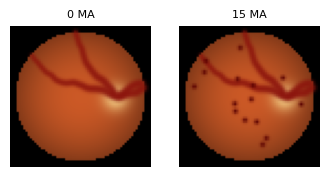

✅ Correcto


In [31]:
# ✅ Comprobación
sin = dibujar_microaneurismas(f17, 17, 0)
con = dibujar_microaneurismas(f17, 17, 15)
assert np.allclose(sin, f17), "Con 0 microaneurismas la imagen no debe cambiar"
assert (con[..., 0] < f17[..., 0] - 0.1).sum() > 10, "Deberían verse puntos oscuros"
fig, axs = plt.subplots(1, 2, figsize=(4, 2))
axs[0].imshow(sin); axs[0].set_title("0 MA", fontsize=8)
axs[1].imshow(con); axs[1].set_title("15 MA", fontsize=8)
[a.axis("off") for a in axs]; plt.show()
print("✅ Correcto")

### ✏️ Ejercicio 4.2 · `dibujar_exudados(img, semilla, n_ex)`

Igual que el anterior, con tres diferencias:
- el dado es `"pos_ex"`;
- el color es amarillo `[1.0, 0.92, 0.35]` y alpha 0.9;
- el radio es **aleatorio** entre 0.9 y 1.8: `rng.uniform(0.9, 1.8)`, sorteado *después* de la posición.

In [32]:
def dibujar_exudados(img, semilla, n_ex):
    rng = dado(semilla, "pos_ex")
    for i in range(n_ex):
        y, x = posicion_en_disco(rng)
        radio = rng.uniform(0.9, 1.8)
        img = pintar_mancha(img, y, x, radio, [1.0, 0.92, 0.35], 0.9)
    return img

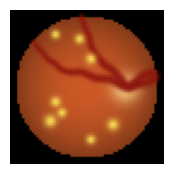

✅ Correcto


In [33]:
# ✅ Comprobación
ex8 = dibujar_exudados(f17, 17, 8)
assert ex8 is not None, "¿Te falta el return?"
assert np.allclose(dibujar_exudados(f17, 17, 0), f17)
assert (ex8[..., 1] > f17[..., 1] + 0.2).sum() > 10, "Deberían verse manchas amarillas (más verde que el fondo)"
plt.figure(figsize=(2, 2)); plt.imshow(ex8); plt.axis("off"); plt.show()
print("✅ Correcto")

### 🤔 Predice

Dibujamos al paciente 17 con 5 microaneurismas y luego con 10. ¿Los 5 de la primera imagen **seguirán en el mismo sitio** en la segunda?

<details><summary>▶ Explicación (después de ejecutar)</summary>

Sí. El dado `"pos_ma"` del paciente 17 siempre produce la misma secuencia de números. El microaneurisma nº 1 usa siempre los primeros números, el nº 2 los siguientes, y así. Pasar de 5 a 10 solo **añade** 5 puntos al final de la secuencia.

Esto completa lo que viste en el notebook 01: allí, al subir la gravedad, el número de lesiones nunca bajaba; ahora, además, **las lesiones que ya había no se mueven**. "El mismo paciente, más grave" se ve como el mismo ojo con más lesiones. Eso es exactamente lo que necesitaremos para los contrafactuales.
</details>

Tu predicción: ...


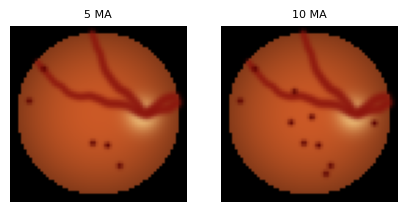

In [34]:
mi_prediccion = "..."
print("Tu predicción:", mi_prediccion)
fig, axs = plt.subplots(1, 2, figsize=(5, 2.5))
axs[0].imshow(dibujar_microaneurismas(f17, 17, 5)); axs[0].set_title("5 MA", fontsize=8)
axs[1].imshow(dibujar_microaneurismas(f17, 17, 10)); axs[1].set_title("10 MA", fontsize=8)
[a.axis("off") for a in axs]; plt.show()

---
## Parte 5 · El escáner de cada hospital

Aquí aparece la flecha `hospital → imagen` del DAG. Cada hospital tiene un escáner que deja su "huella" en la imagen, y esa huella **no tiene nada que ver con la enfermedad**.

### 🔍 Ejemplo: ruido aleatorio con `numpy`

Para el ruido necesitamos un número al azar **por píxel**, y `numpy` los genera todos de golpe: `rng.normal(media, desviacion, forma)`.

`numpy` tiene su propio generador, que se crea con una semilla entera. Para seguir con nuestro sistema de "un dado por variable", sacamos ese entero de nuestro `dado`.

forma del ruido: (64, 64, 3) | media ≈ 0.0002 | desviación ≈ 0.0501


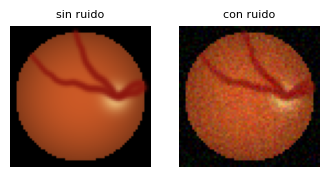

In [35]:
semilla_np = dado(17, "ruido").randrange(2**32)
rng_np = np.random.default_rng(semilla_np)
ruido = rng_np.normal(0, 0.05, (IMG, IMG, 3))
print("forma del ruido:", ruido.shape, "| media ≈", round(ruido.mean(), 4), "| desviación ≈", round(ruido.std(), 4))

con_ruido = np.clip(f17 + ruido, 0, 1)    # np.clip recorta a [0, 1] para que no haya colores imposibles
fig, axs = plt.subplots(1, 2, figsize=(4, 2))
axs[0].imshow(f17); axs[0].set_title("sin ruido", fontsize=8)
axs[1].imshow(con_ruido); axs[1].set_title("con ruido", fontsize=8)
[a.axis("off") for a in axs]; plt.show()

### ✏️ Ejercicio 5.1 · `efecto_escaner(img, hospital, semilla)`

| | Hospital A | Hospital B |
|---|---|---|
| Brillo | igual | más oscuro: `img * 0.8` |
| Viñeteado | no | sí: multiplica por `factor[..., None]` (bordes más oscuros) |
| Ruido | `normal(0, 0.02, ...)` | `normal(0, 0.05, ...)` |
| Marca | **cuadrado blanco** en `img[2:7, 2:7]` (la "etiqueta" del equipo) | no |

Pasos:
1. Crea `rng_np` como en el ejemplo, con el dado `"ruido"` de la `semilla`.
2. Rama `if hospital == "A":`: añade el ruido y luego pinta la marca.
3. Rama `else:`: oscurece, aplica el viñeteado y añade el ruido.
4. Devuelve `np.clip(img, 0, 1)`.

In [43]:
def efecto_escaner(img, hospital, semilla):
    rng_np = np.random.default_rng(dado(semilla, "ruido").randrange(2**32))

    if hospital == "A":
        img = img + rng_np.normal(0, 0.02, (64, 64, 3))
        img[2:7, 2:7] = 1
    else:
        img = img * 0.8
        img = img * factor[..., None]
        img = img + rng_np.normal(0, 0.05, (64, 64, 3))

    return np.clip(img, 0, 1)

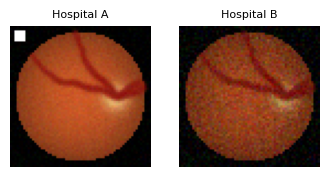

✅ Correcto


In [44]:
# ✅ Comprobación
ia, ib = efecto_escaner(f17, "A", 17), efecto_escaner(f17, "B", 17)
assert ia is not None and ib is not None, "¿Te falta el return?"
assert ia.min() >= 0 and ia.max() <= 1 and ib.min() >= 0 and ib.max() <= 1, "¿Has hecho np.clip?"
assert ia[2:7, 2:7].mean() > 0.99, "Falta la marca blanca en el hospital A"
assert ib[2:7, 2:7].mean() < 0.3, "El hospital B no lleva marca"
assert ib[MASCARA].mean() < ia[MASCARA].mean(), "B debería ser más oscuro que A"
assert np.allclose(efecto_escaner(f17, "B", 17), ib), "La misma semilla debe dar el mismo ruido"
assert np.allclose(f17, fondo_de_ojo(17)), "¡Has modificado la imagen original! Haz img = img + ... en vez de img += ..."
fig, axs = plt.subplots(1, 2, figsize=(4, 2))
axs[0].imshow(ia); axs[0].set_title("Hospital A", fontsize=8)
axs[1].imshow(ib); axs[1].set_title("Hospital B", fontsize=8)
[a.axis("off") for a in axs]; plt.show()
print("✅ Correcto")

---
## Parte 6 · `renderizar(paciente)`: el nodo `imagen` del DAG

### ✏️ Ejercicio 6.1

Recibe el diccionario de un paciente (lo que devuelve `simular_paciente`) y devuelve su imagen. Son cuatro capas, una por línea: fondo → microaneurismas → exudados → escáner.

Fíjate en qué datos del paciente usa: `n_ma`, `n_ex` y `hospital`, que son **exactamente los padres de `imagen` en el DAG**, más la semilla.

In [38]:
def renderizar(paciente):
    s = paciente["semilla"]
    img = fondo_de_ojo(s)
    img = dibujar_microaneurismas(img, s, paciente["n_ma"])
    img = dibujar_exudados(img, s, paciente["n_ex"])
    img = efecto_escaner(img, paciente["hospital"], s)
    return img

{'semilla': 17, 'hospital': 'A', 'edad': 64.78688512674223, 'gravedad': 3, 'n_ma': 18, 'n_ex': 4, 'referable': 1}


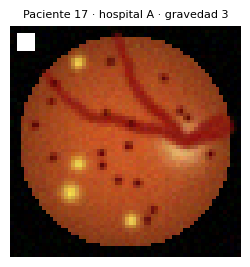

✅ ¡El paciente 17 ya tiene cara!


In [39]:
# ✅ Comprobación
p17 = simular_paciente(17)
img17 = renderizar(p17)
assert img17.shape == (64, 64, 3) and np.allclose(img17, renderizar(p17))
print(p17)
plt.figure(figsize=(3, 3)); plt.imshow(img17); plt.axis("off")
plt.title(f"Paciente 17 · hospital {p17['hospital']} · gravedad {p17['gravedad']}", fontsize=8); plt.show()
print("✅ ¡El paciente 17 ya tiene cara!")

### 🎉 La galería: el mismo paciente bajo distintas intervenciones

Ejecuta y disfruta. Cada columna es una gravedad forzada con `do`, y cada fila un hospital forzado. Es **el mismo ojo** en las 10 imágenes.

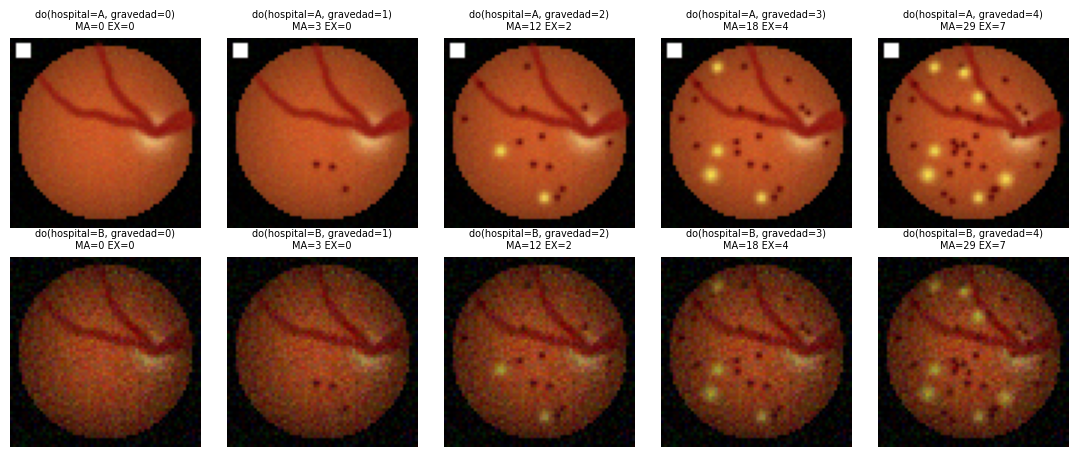

In [40]:
fig, axs = plt.subplots(2, 5, figsize=(11, 4.6))
for i, h in enumerate(["A", "B"]):
    for g in range(5):
        p = simular_paciente(17, do={"hospital": h, "gravedad": g})
        axs[i, g].imshow(renderizar(p)); axs[i, g].axis("off")
        axs[i, g].set_title(f"do(hospital={h}, gravedad={g})\nMA={p['n_ma']} EX={p['n_ex']}", fontsize=7)
plt.tight_layout(); plt.show()

### 🤔 Para pensar

1. Mira la galería: si fueras un modelo que solo ve imágenes de entrenamiento y en ellas los del hospital A suelen estar enfermos, ¿qué sería **más fácil** de aprender, las lesiones o el cuadrado blanco y el brillo?
2. En la galería has forzado el hospital y la gravedad **por separado**. ¿Podrías obtener estas 10 imágenes con datos reales de hospitales?

Pensar estas dos preguntas es la mejor preparación para el notebook 04.

---
## Resumen

| numpy | Para qué lo has usado |
|---|---|
| `np.zeros((h, w, 3))` | Crear una imagen negra en color |
| `img[f, c]`, `img[a:b, c:d]` | Pintar píxeles y rectángulos |
| `np.mgrid` | Saber la fila y columna de cada píxel |
| Operaciones elemento a elemento | Distancias, sombras, manchas, sin bucles |
| Máscaras (`img[D <= R] = ...`) | Pintar solo dentro del disco |
| *Broadcasting* (`[..., None]`) | Aplicar un factor 2D a las 3 capas de color |
| `default_rng(...).normal(...)` | Ruido por píxel |
| `np.clip` | Mantener los valores en [0, 1] |

**Lo que tienes ya:** `simular_paciente(semilla, do)` (el notebook 01) más `renderizar(paciente)` (este) forman un **generador causal de imágenes completo**.

### Siguiente: notebook 03 · El dataset

Generarás miles de pacientes, los guardarás de forma ordenada (aquí aparecerá `pandas`) y harás que la generación sea rápida. Ahora mismo, dibujar 3000 imágenes tardaría bastante, y verás por qué y cómo arreglarlo.